# DATA 266 — Homework 10
## Improving RAG with Reranking, Chunking, and Conversational Memory

**Dataset:** `ccdv/arxiv-summarization`, configuration `document`, first **100** rows of the `train` split.  
**Experiments:** two chunking methods × vector-only/cross-encoder reranking; multi-turn retrieval without/with query memory.  
**Deliverables:** saved vectors (local artifacts), retrieval examples, `METRICS.md`, `RUN_LOG.txt`, `REPORT.md`, figures, and `AI_USE.md`.  

This notebook follows the supplied DATA 266 homework template and the Homework 1 standing requirements. It uses only public Hugging Face models and a local ChromaDB: **no paid API keys are required**. Fill in `SID4` once before using **Runtime → Run all**. The notebook saves measured results; it never fabricates metrics.

In [1]:
import os, random
import numpy as np

# REQUIRED FIRST CODE CELL — exact HW1 personal-parameter formulas.
# Enter your last four SJSU ID digits here, OR set environment variable SJSU_SID4.
SID4 = os.environ.get("SJSU_SID4", "6441")
if not (str(SID4).isdigit() and len(str(SID4)) == 4):
    raise ValueError("Set SID4 to the LAST FOUR digits of your SJSU student ID before Run all.")
SID4 = int(SID4)
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
assert CLS_A != CLS_B
random.seed(SEED)
np.random.seed(SEED)
print(f"SID4={SID4:04d} | SEED={SEED} | SLICE={SLICE} | HP_ID={HP_ID} | CLS_A={CLS_A} | CLS_B={CLS_B}")
print("HW10 does not specify a SLICE, HP_ID, or class-dependent experimental configuration.")

SID4=6441 | SEED=6441 | SLICE=441 | HP_ID=3 | CLS_A=1 | CLS_B=7
HW10 does not specify a SLICE, HP_ID, or class-dependent experimental configuration.


### 1. Setup and reproducibility
The first 100 documents are selected directly from the **unshuffled** `train` stream (we do **not** use `SLICE`, because HW10 specifically says *first 100*). This notebook uses a fixed seed for Python, NumPy and PyTorch. The Colab GPU is optional but recommended for embedding and reranking.

In [2]:
%pip -q install "datasets>=3.5,<5" "sentence-transformers>=3.4,<6" "chromadb>=1.0,<2" "langchain-text-splitters>=0.3,<2" "tabulate>=0.9" "tqdm>=4.66" "pandas>=2.0" "matplotlib>=3.7"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requi

In [3]:
import sys, re, json, time, hashlib, platform, itertools, datetime, traceback
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import chromadb
from datasets import load_dataset
from sentence_transformers import SentenceTransformer, CrossEncoder
from langchain_text_splitters import RecursiveCharacterTextSplitter

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUT = Path("outputs")
FIGS = Path("figures")
DB_PATH = OUT / "chromadb_local"
OUT.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

class Tee:
    """Mirror notebook console output into a real assignment RUN_LOG."""
    def __init__(self, primary, logfile):
        self.primary, self.logfile = primary, logfile
    def write(self, text):
        self.primary.write(text)
        self.logfile.write(text)
        self.logfile.flush()
    def flush(self):
        self.primary.flush()
        self.logfile.flush()

LOG_FILE = open("RUN_LOG.txt", "w", encoding="utf-8")
ORIGINAL_STDOUT, ORIGINAL_STDERR = sys.stdout, sys.stderr
sys.stdout = Tee(ORIGINAL_STDOUT, LOG_FILE)
sys.stderr = Tee(ORIGINAL_STDERR, LOG_FILE)
print("RUN START", datetime.datetime.now(datetime.timezone.utc).isoformat())
print("Environment:", platform.platform(), "Python", platform.python_version(), "Torch", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Parameters:", dict(SID4=f"{SID4:04d}", SEED=SEED, SLICE=SLICE, HP_ID=HP_ID, CLS_A=CLS_A, CLS_B=CLS_B))

RUN START 2026-11-10T20:43:36.863727+00:00
Environment: Linux-6.6.159+-x86_64-with-glibc2.39 Python 3.13.16 Torch 2.14.1+cu130
Device: cuda
Parameters: {'SID4': '6441', 'SEED': 6441, 'SLICE': 441, 'HP_ID': 3, 'CLS_A': 1, 'CLS_B': 7}


### 2. Load and preprocess the actual 100 arXiv articles
ArXiv entries contain pre-tokenized punctuation and tokens such as `@xmath1` and `@xcite`. The preprocessing below normalizes whitespace/punctuation and replaces non-natural-language placeholders, while keeping article paragraphs for the structure-aware splitter. The article, not its abstract, is the retrieval corpus. Abstracts are used only to identify the relevant paper for evaluation.

In [4]:
def clean_article(text):
    """Normalize arXiv tokens without destroying paragraph breaks."""
    text = (text or "").replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"@xmath\d+", " MATH_TOKEN ", text, flags=re.IGNORECASE)
    text = re.sub(r"@xcite(?:\d+)?", " CITATION_TOKEN ", text, flags=re.IGNORECASE)
    lines = []
    for line in text.split("\n"):
        line = re.sub(r"\s+", " ", line).strip()
        line = re.sub(r"\s+([.,!?;:])", r"\1", line)
        if line:
            lines.append(line)
    return "\n".join(lines)

CHUNK_SIZE = 1300
CHUNK_OVERLAP = 180
TOP_K = 5
CANDIDATE_K = 20

SPLITTERS = {
    "fixed": RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP, separators=[""], length_function=len
    ),
    "paragraph": RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP,
        separators=["\n\n", "\n", ". ", " ", ""], length_function=len
    ),
}

def make_chunks(papers, strategy):
    """Return stable IDs, text and provenance for ONE vector collection."""
    splitter = SPLITTERS[strategy]
    chunks = []
    for doc_idx, paper in enumerate(papers):
        for part_idx, text in enumerate(splitter.split_text(paper["article"])):
            if not text.strip():
                continue
            assert len(text) <= CHUNK_SIZE, f"Oversized chunk: {len(text)}"
            chunks.append({
                "id": f"{strategy}-d{doc_idx:03d}-c{part_idx:04d}",
                "text": text,
                "doc_index": doc_idx,
                "paper_id": str(paper["id"]),
                "strategy": strategy,
                "chunk_number": part_idx,
            })
    if not chunks:
        raise ValueError("No chunks were produced. Check dataset loading.")
    assert len(chunks) == len({c["id"] for c in chunks}), "Duplicate chunk IDs"
    return chunks

# Deterministic topic-specific relevance policy, chosen independently of the
# embedding model and cross-encoder. The paper index is grounded in the
# abstract, while the chunk must contain at least two topic cues.
QUERY_SPECS = [
    {
        "id": "Q1", "kind": "standalone",
        "query": "Why do additive models achieve favorable learning rates in high-dimensional problems?",
        "anchor_phrases": ["additive models", "learning rates"],
        "signals": ["additive", "learning rate", "kernel", "high dimension"],
    },
    {
        "id": "Q2", "kind": "standalone",
        "query": "How are current reversals in deterministic ratchet systems connected to bifurcations?",
        "anchor_phrases": ["current reversal", "ratchet"],
        "signals": ["ratchet", "current revers", "bifurcat", "chaotic"],
    },
    {
        "id": "FOLLOWUP", "kind": "followup",
        "query": "How do bifurcations help explain that phenomenon?",
        "anchor_phrases": ["current reversal", "ratchet"],
        "signals": ["ratchet", "current revers", "bifurcat", "chaotic"],
    },
]

def find_target_doc(papers, anchor_phrases):
    matches = []
    for idx, doc in enumerate(papers):
        abstract = doc["abstract"].lower()
        if all(phrase in abstract for phrase in anchor_phrases):
            matches.append(idx)
    if not matches:
        raise ValueError("The first 100 abstracts do not include required topic anchors: " + str(anchor_phrases))
    return matches[0]

def topic_relevance(chunk, spec):
    """Explicit weak/manual-rule label; NOT a substitute for human assessments."""
    if chunk["doc_index"] != spec["target_doc_index"]:
        return False
    text = chunk["text"].lower()
    return sum(signal in text for signal in spec["signals"]) >= 2

def retrieval_metrics(retrieved, gold_ids, k=TOP_K):
    hits = [int(row["id"] in gold_ids) for row in retrieved[:k]]
    hits.extend([0] * (k - len(hits)))
    precision = sum(hits) / k
    recall = sum(hits) / len(gold_ids) if gold_ids else float("nan")
    first = next((rank for rank, hit in enumerate(hits, start=1) if hit), None)
    mrr = 1 / first if first else 0.0
    return {"precision_at_k": precision, "recall_at_k": recall, "mrr": mrr}

class SimpleConversationMemory:
    """Minimal explicit memory: add the preceding question to a follow-up."""
    def __init__(self):
        self.last_user_question = None
    def remember(self, question):
        self.last_user_question = question
    def contextualize(self, followup):
        return (self.last_user_question + " " + followup) if self.last_user_question else followup

In [5]:
print("Loading first 100 rows from the unshuffled document/train stream...")
t0 = time.perf_counter()
data_stream = load_dataset("ccdv/arxiv-summarization", "document", split="train", streaming=True)
raw_docs = list(itertools.islice(data_stream, 100))
assert len(raw_docs) == 100, f"Expected 100 documents; got {len(raw_docs)}"
papers = []
for i, row in enumerate(raw_docs):
    article = clean_article(row["article"])
    abstract = clean_article(row["abstract"])
    if not article or not abstract:
        raise ValueError(f"Missing article or abstract at dataset position {i}")
    papers.append({"id": row.get("id", f"train-{i:03d}"), "article": article, "abstract": abstract})
print(f"Loaded 100 full articles in {time.perf_counter() - t0:.1f}s")
print("Characters:", sum(len(p["article"]) for p in papers))
print("First abstract:", papers[0]["abstract"][:280], "...")

README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

### 3. Chunking strategies and gold labels
The chunk size and overlap are the **same** for both strategies (1,300 and 180 characters), so the main difference is boundary selection. Strategy A uses strict fixed-width character windows. Strategy B prefers paragraph/line/sentence/word boundaries before falling back to characters. The label policy is an *explicit, imperfect lexical relevance proxy*: a chunk must come from the abstract-identified paper **and** mention at least two paper-specific concepts. This keeps the same judgment rule across baseline and reranked retrieval and avoids evaluating the reranker by its own score. It is not a human-rated gold standard.

In [6]:
chunk_sets = {name: make_chunks(papers, name) for name in SPLITTERS}
for spec in QUERY_SPECS:
    spec["target_doc_index"] = find_target_doc(papers, spec["anchor_phrases"])
    print(f"{spec['id']} target paper: index {spec['target_doc_index']} | {spec['query']}")
for name, chunks in chunk_sets.items():
    lengths = [len(c["text"]) for c in chunks]
    print(f"{name}: {len(chunks):,} chunks | mean chars {np.mean(lengths):.1f} | max {max(lengths)}")
    for spec in QUERY_SPECS:
        print(f"  {spec['id']} relevant chunks: {sum(topic_relevance(c,spec) for c in chunks)}")
        assert any(topic_relevance(c,spec) for c in chunks), f"No relevance labels: {name} {spec['id']}"
print("Example fixed chunk:", chunk_sets["fixed"][0]["text"][:290])
print("Example paragraph-aware chunk:", chunk_sets["paragraph"][0]["text"][:290])

### 4. Embed and index in persistent ChromaDB
We use `sentence-transformers/all-MiniLM-L6-v2` for normalized document and query embeddings; Chroma stores both strategies in separate cosine collections. The database is rebuilt on each full run to avoid silently mixing data from earlier configurations.

In [7]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
print("Loading embedding model:", EMBED_MODEL)
embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
print("Loading cross-encoder reranker:", RERANK_MODEL)
reranker = CrossEncoder(RERANK_MODEL, device=DEVICE)

client = chromadb.PersistentClient(path=str(DB_PATH))
collections = {}
EMBED_BATCH_SIZE = 64
CHROMA_BATCH_SIZE = 256

for strategy, chunks in chunk_sets.items():
    collection_name = "hw10_" + strategy
    try:
        client.delete_collection(collection_name)
    except ValueError:
        pass  # first run; no collection yet
    except Exception as exc:
        if "does not exist" not in str(exc).lower() and "not found" not in str(exc).lower():
            raise
    col = client.create_collection(name=collection_name, metadata={"hnsw:space": "cosine"})
    print(f"Indexing {strategy}: {len(chunks)} chunks")
    started = time.perf_counter()
    for start in tqdm(range(0, len(chunks), CHROMA_BATCH_SIZE), desc=f"{strategy} embeddings"):
        batch = chunks[start:start + CHROMA_BATCH_SIZE]
        embeddings = embedder.encode([c["text"] for c in batch],
                                     batch_size=EMBED_BATCH_SIZE, convert_to_numpy=True,
                                     normalize_embeddings=True, show_progress_bar=False)
        col.add(ids=[c["id"] for c in batch],
                documents=[c["text"] for c in batch],
                embeddings=embeddings.tolist(),
                metadatas=[{"doc_index": c["doc_index"], "paper_id": c["paper_id"],
                            "chunk_number": c["chunk_number"]} for c in batch])
    print(f"Indexed {strategy} in {time.perf_counter()-started:.1f}s; Chroma count={col.count()}")
    assert col.count() == len(chunks)
    collections[strategy] = col

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (13 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

fixed embeddings:   0%|          | 0/13 [00:00<?, ?it/s]

paragraph embeddings:   0%|          | 0/14 [00:00<?, ?it/s]

### 5. Retrieval with and without reranking
For fairness, both methods start with the same top-20 cosine candidates. The vector-only system returns its top five. Reranking uses the same 20 candidates but scores each `(question, chunk)` pair with a cross-encoder before selecting the top five. The cross-encoder scores and cosine distances are not directly comparable.

In [8]:
def retrieve(question, strategy, rerank=False, k=TOP_K, candidate_k=CANDIDATE_K):
    col = collections[strategy]
    query_embedding = embedder.encode([question], normalize_embeddings=True, convert_to_numpy=True)[0]
    result = col.query(query_embeddings=[query_embedding.tolist()], n_results=min(candidate_k, col.count()),
                       include=["documents", "metadatas", "distances"])
    rows = []
    for cid, document, meta, distance in zip(result["ids"][0], result["documents"][0],
                                              result["metadatas"][0], result["distances"][0]):
        rows.append({"id": cid, "text": document, "doc_index": int(meta["doc_index"]),
                     "paper_id": meta["paper_id"], "vector_distance": float(distance)})
    if rerank:
        scores = reranker.predict([(question, r["text"]) for r in rows], batch_size=16,
                                  show_progress_bar=False)
        for row, score in zip(rows, np.asarray(scores).reshape(-1)):
            row["rerank_score"] = float(score)
        rows.sort(key=lambda x: x["rerank_score"], reverse=True)
    return rows[:k]

for spec in QUERY_SPECS[:2]:
    print("\nSAMPLE QUERY:", spec["query"])
    for strategy in SPLITTERS:
        for rerank_flag in (False, True):
            hits = retrieve(spec["query"], strategy, rerank=rerank_flag)
            print(strategy, "rerank" if rerank_flag else "vector-only",
                  [(r["id"], r["doc_index"]) for r in hits])
            print("  top evidence:", hits[0]["text"][:220].replace("\n", " "))

### 6. Conversational memory: controlled two-turn test
The second question — “How do bifurcations help explain that phenomenon?” — intentionally omits the subject. The **without-memory** system searches that bare follow-up. The **with-memory** system concatenates the preceding user question, so the referent “current reversal in deterministic ratchet systems” is available. Both are evaluated against the same paper-specific relevance rule.

In [9]:
turn1 = "What is current reversal in deterministic ratchet systems?"
turn2 = QUERY_SPECS[2]["query"]
conversation = SimpleConversationMemory()
conversation.remember(turn1)
contextualized = conversation.contextualize(turn2)
print("Turn 1:", turn1)
print("Turn 2:", turn2)
print("Without memory (search string):", turn2)
print("With memory (search string):", contextualized)
for strategy in SPLITTERS:
    no_mem = retrieve(turn2, strategy, rerank=False)
    yes_mem = retrieve(contextualized, strategy, rerank=False)
    print(strategy, "no-memory papers:", [r["doc_index"] for r in no_mem])
    print(strategy, "memory-on papers:", [r["doc_index"] for r in yes_mem])

### 7. Precision@5, Recall@5 and MRR (consistent relevance rubric)
A relevant chunk is a chunk belonging to the matching paper **and** containing at least two topic signals. `gold_ids` is computed over **all** chunks in each strategy, not just the retrieved top five. Thus Precision@5 = relevant among top-five / 5; Recall@5 = relevant top-five / all rubric-matching chunks in that index; MRR = reciprocal rank of the first relevant chunk (or 0). These are *proxy-label chunk-level* metrics, not independently human-annotated relevance scores.

In [10]:
metric_rows, retrieval_rows, judgment_rows = [], [], []
for strategy, chunks in chunk_sets.items():
    for spec in QUERY_SPECS:
        gold = {c["id"] for c in chunks if topic_relevance(c, spec)}
        for c in chunks:
            judgment_rows.append({"strategy": strategy, "query_id": spec["id"],
                                  "chunk_id": c["id"], "doc_index": c["doc_index"],
                                  "relevant": int(c["id"] in gold)})
        memory_modes = [False, True] if spec["kind"] == "followup" else [False]
        for memory_on in memory_modes:
            search_question = contextualized if (memory_on and spec["kind"] == "followup") else spec["query"]
            for reranking in (False, True):
                started = time.perf_counter()
                found = retrieve(search_question, strategy, rerank=reranking)
                latency_ms = (time.perf_counter() - started) * 1000.0
                scores = retrieval_metrics(found, gold)
                metric_rows.append({"strategy": strategy, "query_id": spec["id"],
                                    "type": spec["kind"], "reranking": reranking,
                                    "memory": memory_on, "k": TOP_K, "gold_chunks": len(gold),
                                    "latency_ms": latency_ms, **scores})
                for rank, item in enumerate(found, 1):
                    retrieval_rows.append({"strategy": strategy, "query_id": spec["id"],
                                           "reranking": reranking, "memory": memory_on,
                                           "rank": rank, "chunk_id": item["id"],
                                           "doc_index": item["doc_index"],
                                           "is_relevant": int(item["id"] in gold),
                                           "retrieval_query": search_question,
                                           "excerpt": item["text"][:300].replace("\n", " ")})

results = pd.DataFrame(metric_rows)
retrieval_df = pd.DataFrame(retrieval_rows)
judgments = pd.DataFrame(judgment_rows)
assert len(results) == 16, f"Expected 16 experiment rows, got {len(results)}"
assert results[["precision_at_k", "recall_at_k", "mrr"]].notna().all().all()
for metric in ("precision_at_k", "recall_at_k", "mrr"):
    assert results[metric].between(0, 1).all(), f"Out-of-range values in {metric}"
results.to_csv(OUT / "metrics_results.csv", index=False)
retrieval_df.to_csv(OUT / "retrieval_examples.csv", index=False)
judgments.to_csv(OUT / "relevance_judgments.csv", index=False)
print("\nMEASURED METRICS")
print(results.to_string(index=False, float_format=lambda n: f"{n:.4f}"))

### 8. Compare changes and visualize findings
The chart compares retrieval with and without reranking for both chunking strategies across the two standalone queries. A separate table compares memory on/off on the same follow-up. Error analysis lists incorrectly retrieved chunks and missed relevant chunks — with source IDs and excerpts rather than invented cases.

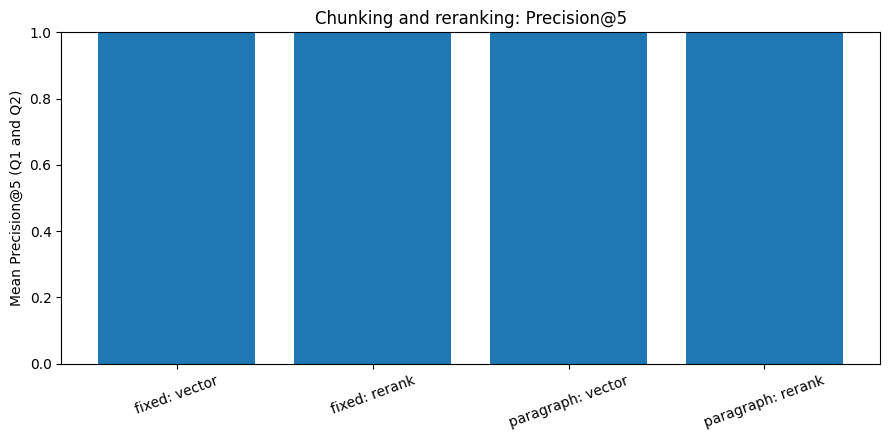

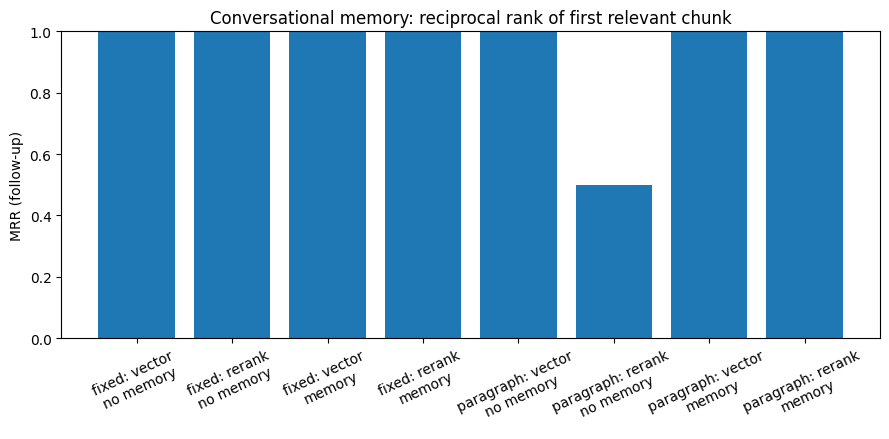

In [11]:
standalone = results[results["type"] == "standalone"]
summary = standalone.groupby(["strategy", "reranking"], as_index=False)[
    ["precision_at_k", "recall_at_k", "mrr"]].mean()
print("\nSTANDALONE QUERY MEANS")
print(summary.to_string(index=False, float_format=lambda n: f"{n:.4f}"))
print("\nFOLLOW-UP MEMORY COMPARISON")
print(results[results["type"] == "followup"].to_string(index=False, float_format=lambda n: f"{n:.4f}"))

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [f"{r.strategy}: {'rerank' if r.reranking else 'vector'}" for r in summary.itertuples()]
ax.bar(labels, summary["precision_at_k"])
ax.set_ylabel("Mean Precision@5 (Q1 and Q2)")
ax.set_ylim(0, 1)
ax.set_title("Chunking and reranking: Precision@5")
ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
fig.savefig(FIGS / "precision_comparison.png", dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
fm = results[results["type"] == "followup"].copy()
labels = [f"{r.strategy}: {'rerank' if r.reranking else 'vector'}\n{'memory' if r.memory else 'no memory'}"
          for r in fm.itertuples()]
ax.bar(labels, fm["mrr"])
ax.set_ylabel("MRR (follow-up)")
ax.set_ylim(0, 1)
ax.set_title("Conversational memory: reciprocal rank of first relevant chunk")
ax.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
fig.savefig(FIGS / "memory_comparison.png", dpi=170)
plt.show()

false_positives = retrieval_df[retrieval_df["is_relevant"] == 0].head(8)
false_positives.to_csv(OUT / "retrieval_errors.csv", index=False)
print("\nFALSE POSITIVES / OFF-TOPIC EXAMPLES")
for row in false_positives.itertuples():
    print(f"{row.query_id} {row.strategy} rerank={row.reranking} memory={row.memory}",
          f"rank={row.rank}", f"chunk={row.chunk_id}", "|", row.excerpt[:180])

### 9. Export Git submission reports using the **actual** results
This cell writes `METRICS.md` and `REPORT.md` from the measured data. It also records package versions/configuration, saves a sample of retrieval evidence, closes the run log and produces a convenient ZIP of Git-appropriate text/notebook artifacts. The full Chroma vector folder is excluded from Git because it can be regenerated from the notebook.

In [13]:
def markdown_table(df):
    return df.to_markdown(index=False, floatfmt=".4f")

def best_change_text(df, metric, field, field_values, context):
    subset = df.copy()
    left = subset[subset[field] == field_values[0]][metric].mean()
    right = subset[subset[field] == field_values[1]][metric].mean()
    delta = right - left
    label = "improved" if delta > 1e-9 else ("decreased" if delta < -1e-9 else "was unchanged")
    return (f"{context}: mean {metric} was {left:.4f} for {field}={field_values[0]} "
            f"and {right:.4f} for {field}={field_values[1]} "
            f"(change {delta:+.4f}); performance {label} under these proxy labels.")

metric_display = results[["strategy", "query_id", "reranking", "memory", "gold_chunks",
                          "precision_at_k", "recall_at_k", "mrr", "latency_ms"]]
metrics_markdown = f"""# DATA 266 — Homework 10 Metrics

**Student SID4:** {SID4:04d}
**Seed:** {SEED}
**Dataset:** ccdv/arxiv-summarization / document / train / first 100 documents
**Chunk sizes:** {CHUNK_SIZE} characters; overlap {CHUNK_OVERLAP} for both splitters
**Top K:** {TOP_K}; **Candidate pool:** {CANDIDATE_K}
**Embedding:** `{EMBED_MODEL}`
**Vector DB:** persistent ChromaDB, cosine distance
**Reranker:** `{RERANK_MODEL}`
**Relevance:** paper/keyword proxy labels; not independent human annotations

## All measured conditions

{markdown_table(metric_display)}

## Standalone query mean (Q1 and Q2)

{markdown_table(summary)}

## Interpretation guidance

Recall@5 is the fraction of **all rule-relevant chunks** returned among the top five for each index. It is not document-level recall and its denominator differs between the two chunking strategies. MRR@5 uses rank of the first relevant chunk. Measured latency is environment dependent. This rubric is not an independently curated gold standard.
"""
Path("METRICS.md").write_text(metrics_markdown, encoding="utf-8")

reranking_sentence = best_change_text(standalone, "mrr", "reranking", (False, True), "Reranking (Q1/Q2 combined)")
fixed_vs_para = best_change_text(standalone[standalone["reranking"] == False], "mrr", "strategy",
                                 ("fixed", "paragraph"), "Chunking (no rerank)")
followup = results[results["type"] == "followup"]
memory_sentence = best_change_text(followup, "mrr", "memory", (False, True), "Conversational memory (follow-up)")

err_rows = false_positives.head(5)
if len(err_rows):
    error_markdown = "\n".join(
        f"- **{r.query_id}/{r.strategy}, rank {r.rank}:** `{r.chunk_id}` was retrieved "
        f"but did not satisfy the declared topic-evidence rule. Excerpt: {r.excerpt[:160]}..."
        for r in err_rows.itertuples()
    )
else:
    error_markdown = "- No false positive was observed within the reported top-five results under this rule."

report = f"""# DATA 266 — HW10: Improving RAG

## 1. Objective
I compared retrieval quality when I varied text chunking, reranking, and the handling of follow-up queries.

## 2. Dataset and preprocessing
I loaded the first **100** articles from the unshuffled `ccdv/arxiv-summarization` `document/train` split (not the pre-chunked `section` config). I normalized whitespace and punctuation, replaced arXiv math/citation placeholders, and indexed the **article** field rather than the abstract.

## 3. Experiment design
- Fixed-width character chunking versus paragraph/sentence-preferred splitting, both size **{CHUNK_SIZE}** and overlap **{CHUNK_OVERLAP}**.
- Normalized MiniLM embeddings indexed separately in local Chroma cosine collections.
- Top-20 vector candidates; compare vector top-five with cross-encoder-reranked top-five.
- Q1: {QUERY_SPECS[0]['query']}
- Q2: {QUERY_SPECS[1]['query']}
- Memory: first ask “{turn1}” then “{turn2}”. The memory version augments the follow-up with the prior question; the baseline does not.

## 4. Evaluation
I used **Precision@5, Recall@5 and MRR@5**. Relevance is defined by a transparent topical-paper rule: the chunk must belong to the article identified by the corresponding abstract and must contain at least two pre-declared topic cues. I applied the same labels regardless of reranking. This is a **weak manual-rule proxy**, not hand-annotated ground truth. Different splitter boundaries can create different numbers of relevant chunks, so I interpret cross-strategy Recall@5 cautiously.

## 5. Results

{markdown_table(summary)}

### Reranking
{reranking_sentence}

### Chunking
{fixed_vs_para}

### Conversational memory
{memory_sentence}

### Complete measures
See `METRICS.md` and `outputs/metrics_results.csv`.

## 6. Error analysis
The following cases are *observed* off-topic / nonmatching retrievals according to the declared gold-label rule. Some may actually be useful semantically, a limitation of lexical relevance proxies.

{error_markdown}

## 7. Limitations and conclusion
I used two queries grounded in papers within the required first 100 articles; this is too small to generalize to other scientific topics. The gold-label policy favors target-paper matches and literal topic mentions. Reranking and query expansion have additional runtime costs; timing results depend on hardware. A stronger follow-up study would add blinded human relevance labels across the merged top-20 pools and more diverse queries. These findings describe the measured conditions only, not a universal winner.
"""
Path("REPORT.md").write_text(report, encoding="utf-8")

config = {"sid4": f"{SID4:04d}", "seed": SEED, "slice": SLICE, "hp_id": HP_ID,
          "cls_a": CLS_A, "cls_b": CLS_B, "dataset": "ccdv/arxiv-summarization",
          "config": "document", "split": "train", "first_n": len(papers),
          "chunk_size": CHUNK_SIZE, "chunk_overlap": CHUNK_OVERLAP,
          "top_k": TOP_K, "candidate_k": CANDIDATE_K,
          "embedding_model": EMBED_MODEL, "reranker": RERANK_MODEL,
          "python": platform.python_version(), "torch": torch.__version__,
          "chromadb": chromadb.__version__, "device": DEVICE,
          "run_ended_utc": datetime.datetime.now(datetime.timezone.utc).isoformat()}
(OUT / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("RUN SUCCESS", datetime.datetime.now(datetime.timezone.utc).isoformat())
print("Saved:", "METRICS.md, REPORT.md, RUN_LOG.txt, outputs/*.csv, outputs/run_config.json, figures/*.png")
print("IMPORTANT: Save the EXECUTED notebook with its outputs intact before committing to Git.")
sys.stdout.flush()
sys.stderr.flush()
sys.stdout, sys.stderr = ORIGINAL_STDOUT, ORIGINAL_STDERR
LOG_FILE.close()

from zipfile import ZipFile, ZIP_DEFLATED
archive_name = f"hw10_measured_results_{SID4:04d}.zip"
paths = [Path("METRICS.md"), Path("REPORT.md"), Path("RUN_LOG.txt")]
paths += list(OUT.glob("*.csv")) + list(OUT.glob("*.json")) + list(FIGS.glob("*.png"))
with ZipFile(archive_name, "w", ZIP_DEFLATED) as zf:
    for p in paths:
        zf.write(p, p.as_posix())
print("Exported measured files:", archive_name)

RUN SUCCESS 2026-11-10T20:51:13.091846+00:00
Saved: METRICS.md, REPORT.md, RUN_LOG.txt, outputs/*.csv, outputs/run_config.json, figures/*.png
IMPORTANT: Save the EXECUTED notebook with its outputs intact before committing to Git.
Exported measured files: hw10_measured_results_6441.zip


### 10. Submission checklist

- [ ] Replace `SID4` in the first code cell with my own last four digits.
- [ ] Run the notebook **top to bottom** with internet enabled (Colab GPU recommended), and save the **executed `.ipynb` with outputs intact**.
- [ ] Confirm `RUN SUCCESS` appears at the end; verify actual numbers in `METRICS.md` and `REPORT.md`.
- [ ] Read the `AI_USE.md` appendix and edit it to reflect my own work and the errors I personally encountered; do not submit unverified claims.
- [ ] Commit this notebook plus `RUN_LOG.txt`, `METRICS.md`, `REPORT.md`, `AI_USE.md`, figures, and small `outputs/*.csv` and `outputs/*.json` artifacts to my **private** `data266-<SID4>` Git repository.
- [ ] Share the private repository with the instructor and grading team; create/push the **`hw10`** tag; submit its repository URL to Canvas.

**Important:** Do not commit the giant `outputs/chromadb_local/` database, cached models, credentials, or downloaded dataset files. The notebook rebuilds them. The Homework 1 standing instructions request meaningful incremental commits rather than only one final commit.